<a href="https://colab.research.google.com/github/Gchirico63/Didattica/blob/main/AI_ExperimentalPhysics/PulseSound_and_beating.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

how many samplings?;  13230  with sampling time = 0.022675736961451247  ms
 Nyquist limits are: delta_f = 6.667  Hz and f_max = 44100.0  Hz
spectrum centered at f0= 220  Hz
width is  5.5  Hz
pulse width is  1.142  s


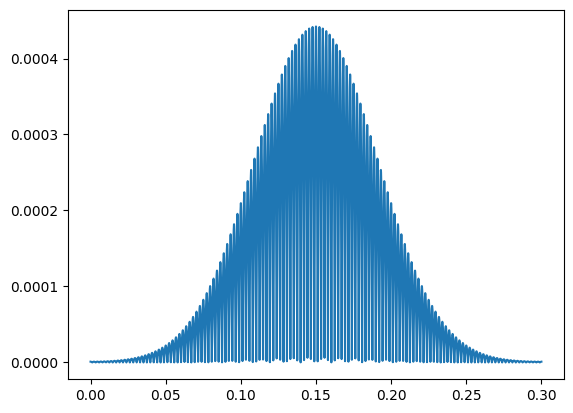

In [41]:
import matplotlib.pyplot as plt
import numpy as np

t0=0
t1= 0.3
sample_rate=44100
Np = int((t1-t0)*sample_rate)
dt = (t1-t0)/Np ### sampling time
print ('how many samplings?; ', Np, ' with sampling time =',1000*dt, ' ms')
print (' Nyquist limits are: delta_f =', np.round(2/(t1-t0),3),' Hz and f_max =',1/dt,' Hz')
tempo = np.linspace(t0,t1,Np)

Freq = np.fft.fftfreq(Np,tempo[1]-tempo[0])

f00 = 220
gamma  = f00/40.
Spettro = np.exp(-(Freq-f00)**2/gamma**2)
Spettro = Spettro + np.exp(-(Freq+f00)**2/gamma**2)

SignalPulse = np.fft.fftshift(np.fft.ifft(np.fft.fftshift(Spettro)))
plt.figure()
plt.plot(tempo,np.abs(SignalPulse))

print ('spectrum centered at f0=',f00,' Hz')
print ('width is ',gamma,' Hz')
print ('pulse width is ',np.round(2*np.pi/gamma,3),' s')

play_sound(np.abs(SignalPulse),sr)

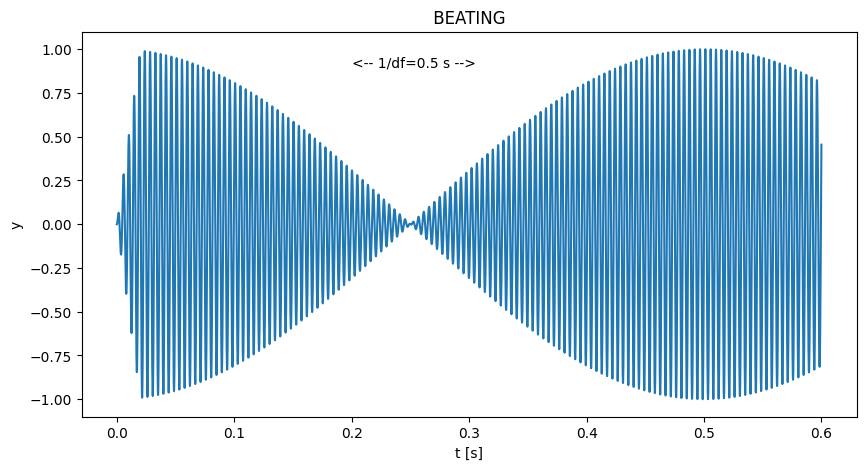

In [57]:
'''
generate sound
'''

import numpy as np

def generate_harmonic_tone(f0=440.0, duration=2.0, harmonics=(1.0, 0.5, 0.25), sample_rate=44100):
    """Generate a smooth harmonic waveform from fundamental frequency f0 and harmonic weights."""
    t = np.linspace(0, duration, int(sample_rate * duration), endpoint=False)

    # Sum fundamental (n=1) and integer multiples (n=2, 3, ...)
    signal = sum(
        amp * np.sin(2 * np.pi * (n + 1) * f0 * t)
        for n, amp in enumerate(harmonics)
    )

    # Normalize to prevent clipping
    peak = np.max(np.abs(signal))
    if peak > 0:
        signal = 0.5 * signal / peak

    # Apply 20 ms fade-in/fade-out to avoid speaker clicks
    fade_len = min(int(0.02 * sample_rate), len(signal) // 2)
    envelope = np.ones_like(signal)
    envelope[:fade_len] = np.linspace(0, 1, fade_len)
    envelope[-fade_len:] = np.linspace(1, 0, fade_len)
    return signal * envelope, sample_rate


def play_sound(signal, sample_rate=44100, fallback_wav="tone.wav"):
    """Play audio in Colab/Jupyter, local desktop (sounddevice), or save as WAV."""
    # 1. Try IPython/Colab/Jupyter browser widget first
    try:
        shell = get_ipython().__class__.__name__  # noqa: F821
        if shell in ("ZMQInteractiveShell", "Shell"):  # Jupyter or Google Colab
            from IPython.display import Audio, display
            display(Audio(signal, rate=sample_rate, autoplay=True))
            return
    except NameError:
        pass

    # 2. Try local audio hardware (Spyder / terminal on macOS, Linux, Windows)
    try:
        import sounddevice as sd
        sd.play(signal, samplerate=sample_rate)
        sd.wait()
        return
    except Exception:
        pass

    # 3. Universal fallback: write a standard 16-bit WAV file
    from scipy.io.wavfile import write
    pcm16 = np.int16(signal * 32767)
    write(fallback_wav, sample_rate, pcm16)
    print(f"No interactive audio output available; saved to {fallback_wav}")


# --- Usage ---
# Pure constant frequency (only 1st harmonic)
#f00 = 220
deltaf = 2
pure_wave, sr = generate_harmonic_tone(f0=f00, duration=3, harmonics=(1.0,))
pure_wave2, sr = generate_harmonic_tone(f0=f00+deltaf, duration=3, harmonics=(1.0,))
Nttempo = pure_wave.size
tt0 = 0
tt1 = Nttempo  / sr
ttempo = np.linspace(tt0,tt1,Nttempo)

plt.figure('beating',figsize=(10,5))
plt.title(' BEATING ')
mm = 5
plt.plot(ttempo[0:int(Nttempo/mm)],pure_wave[0:int(Nttempo/mm)]+pure_wave2[0:int(Nttempo/mm)])
plt.xlabel('t [s]')
plt.ylabel('y')
plt.text(0.2,0.9,'<-- 1/df='+str(1/deltaf)+' s -->')
# Rich harmonic tone (f0 + 2*f0 + 3*f0 + 4*f0)
rich_wave, sr = generate_harmonic_tone(f0=220.0, duration=2.0, harmonics=(1.0, 1.01))




In [ ]:
print ('playing a pure harmonic at f0 = ',f00)
play_sound(rich_wave, sr)
print ('playing the beating at f0 and f0+Deltaf= ')
play_sound(pure_wave+pure_wave2, sr)
print ('playing a pulse at f0 = ', f00)
play_sound(np.abs(SignalPulse),sr)


playing a pure harmonic at f0 =  220


playing the beating at f0 and f0+Deltaf= 


playing a pulse at f0 =  220
